# TL;DR:

KMeans: fit, predict, inertia, centroids

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
model.fit(samples)
labels = model.predict(samples)
model.fit_predict(samples) # why not both on same sample?
centroids = model.cluster_centers_ # x and y coordinates of centroids
inertia = model.inertia_ # lower = better

crosstab: "confusion matrix"
```python
import pandas as pd 
pd.crosstab(index = df['labels'], columns = df['varieties'])

Pipelines: standardscaler + kmeans
```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
kmeans = KMeans()
pipeline = make_pipeline(scaler, kmeans)
pipeline.fit(samples)

Normalizer: tricky
- normalization per row, and not column
- normalization per sample, and not feature

```python
from sklearn.preprocessing import Normalizer
import pandas as pd 
df = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv').filter(regex = '\d-')

norm = Normalizer()

(
    pd.DataFrame(
        norm.fit_transform(df))
    .applymap(lambda x: x**2)
    .sum(axis = 1)
    ) # all results are 1

unit norm (from normalizer)  
In machine learning, a unit norm is a vector that has a length or magnitude of 1. It is used to normalize the data so that the magnitude of the features does not affect the performance of the model. The most common unit norm is the L2 norm, which is also known as the Euclidean norm. It is defined as the square root of the sum of the squared values of each element in the vector. Other norms include L1 norm and max norm1.

Dendrogram, linkage

```python
from scipy.cluster.hierarchy import linkage, dendrogram 

#calculate the linkage: with single, it's bad
mergings = linkage(df.drop('label', axis = 1), method = 'single')

# plot dendrogram
dendrogram(
    mergings, 
    labels = df['label'].values,
    leaf_rotation=90,
    leaf_font_size=6
)
plt.show()


# 1: Unsupervised learning

Unsupervised learning finds patterns in data ...  
but __without__ a specific prediction task in mind!



Datase: Iris  
- 3 species: Setosa, Versicolor, Virginica   
  
- 4 features: 
    - for each [Petal,Sepal]:
        - length,  width  



Iris data is 4-dimensional
- Columns are measurements (the __features__)
- Rows represent iris plants (the __samples__)

K-means clustering
- Finds clusters of samples
- Number of flusters must be specified

https://www.youtube.com/watch?v=4b5d3muPQmA
- clustering algorithm: aims to partition n observations into k clusters

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
model.fit(samples)

labels = model.predict(samples)
print(labels)

new_labels = model.predict(new_samples)
print(new_labels)

import matplotlib.pyplot as plt
xs = samples[:,0]
ys = samples[:,2]
plt.scatter(xs, ys, c = labels)
plt.show()
```

cluster labels for new samples
- new samples can be assigned to existing clusters
- k-means remembers the mean of each cluster (the "centroids")
- finds the nearest centroid to each  new sample 

Time to practice!

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Text(0.5, 1.0, 'KNN: 3 clusters. Centroids: black "diamonds"')

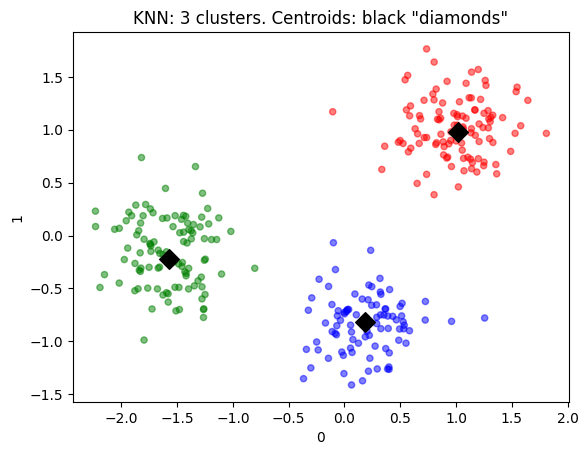

In [1]:
# import KMeans
from sklearn.cluster import KMeans 
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 

# Import dataset 
points = pd.read_csv('tables/points.csv')
new_points = pd.read_csv('tables/new_points.csv')

# Create a KMEans instance with 3 clusters: model
model = KMeans(n_clusters = 3)

# fit model to points
model.fit(points)

# Determine the cluser labels of new_points: labels
labels = model.predict(new_points)
dic = {0:'r', 1:'g', 2:'b'}

labels2 = [dic[k] for k in labels]
ax = new_points.plot.scatter(0,1, c = labels2, alpha = 0.5)

# Assign the cluster centers: centroids
centroids = model.cluster_centers_ 
pd.DataFrame(centroids).plot.scatter(0,1, ax = ax, marker = 'D', s = 100 , c = 'k')

plt.title('KNN: 3 clusters. Centroids: black "diamonds"')

Evaluating a cluster: intertia

- Check correspondence. Ex: Iris species - compare 3 species with KNN 3 clusters

```python
import pandas as pd 
df = pd.DataFrame({'labels': labels, 'species': species})
ct = pd.crosstab(df['labels'], df['species'])
```


Intertia measures clustering quality
- lower is better

```python
from sklearn import KMeans

model = KMeans(n_clusters = 3)
model.fit(samples)
print(model.inertia_)
```
- More clusters -> lower inertia

How many clusters to choose? Inertia vs n_clusters
- choose the "elbow"

Let's pratice!

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will c

Text(0.5, 1.0, 'seed length vs width, the KMeans groups and centroids')

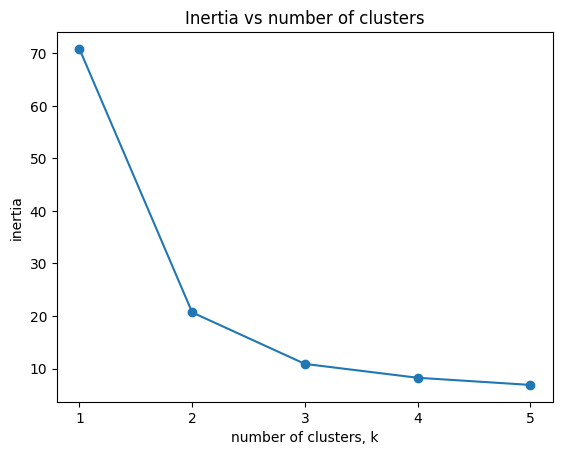

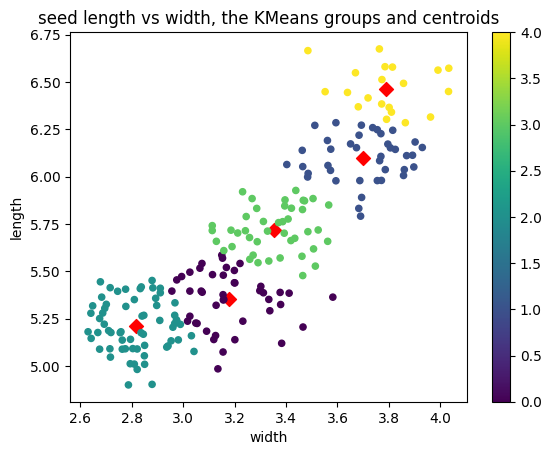

In [26]:
import pandas as pd 
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

ks = range(1,6)
inertias = []

samples = pd.read_csv('tables/seeds-width-vs-length.csv', header = None).set_axis(['width','length'], axis = 1)

for k in ks:
    # Create a KMeans instance with k clusters:
    model = KMeans(n_clusters = k)

    # Fit model to samples
    model.fit(samples)

    # append the inertia to the list of inertias
    inertias.append(model.inertia_)

# plot ks vs inertias
plt.plot(ks, inertias, '-o')
plt.xlabel('number of clusters, k')
plt.ylabel('inertia')
plt.xticks(ks)
plt.title('Inertia vs number of clusters')


## by sergio
centroids = model.cluster_centers_
ax = pd.DataFrame(centroids).plot.scatter(0,1, s = 50, marker = 'D', c= 'red')

samples.plot.scatter(x = 'width', y = 'length', c = model.predict(samples), cmap = 'viridis', ax = ax)
plt.title('seed length vs width, the KMeans groups and centroids')

In [33]:
pd.read_csv('tables/seeds-width-vs-length-varieties.csv')

,length,width,varieties
0,3.312,5.763,Kama wheat
1,3.333,5.554,Kama wheat
2,3.337,5.291,Kama wheat
3,3.379,5.324,Kama wheat
4,3.562,5.658,Kama wheat
...,...,...,...
205,2.981,5.137,Canadian wheat
206,2.795,5.140,Canadian wheat
207,3.232,5.236,Canadian wheat
208,2.836,5.175,Canadian wheat


In [1]:
# Create a KMeans model with 3 clusters: model
model =KMeans(n_clusters = 3)

# Use fit_predict to fit model to obtain cluster labels: labels
samples = pd.read_csv('tables/seeds-width-vs-length-varieties.csv')
labels = model.fit_predict(samples[['width','length']])

# create a DataFrame with labels and varieties as columns: df
samples['labels'] = labels
samples

# create crosstab: ct
ct = pd.crosstab(samples['labels'], samples['varieties'])
ct

NameError: name 'KMeans' is not defined

Transforming features for better clustering

Dataset: Piedment wines
- 3 distinct varieties: Barolo, Grignolino and Barbera

Poor fitting: very different variances: data not concave?
```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
labels = model.fit_predict(samples)

StandardScaler

0 mean and variance 1

```python
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(samples)
StandardScaler(copy = True, with_mean = True, with_std = True)
samples_scaled = scaler.transform(samples) # note that it is not predict()

StandardScaler, then KMeans: pipeline
Better fitting
```python
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
kmeans = KMeans(n_clusters = 3)
pipeline = make_pipeline(scaler, kmeans)
pipeline.fit(samples)

Obs: other preprocessing steps:
- StandardScaler
- MaxAbsScaler
- Normalizer

Time to Practice!


In [10]:
# perform necessary imports 
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans 
import pandas as pd 

# import data
samples = pd.read_csv('tables/fish.csv')

# create scaler
scaler = StandardScaler()

# create Kmeans
kmeans = KMeans(n_clusters = 4)

# create pipeline
pipeline = make_pipeline(scaler, kmeans)


In [13]:
# fit the pipeline to samples
pipeline.fit(samples.filter(regex = '\d')) #removing samples col

# calculate the cluster labels
labels = pipeline.predict(samples.filter(regex = '\d'))

# add labels to samples 
samples['labels'] = labels
# create crosstab
ct = pd.crosstab(samples['labels'], samples['species'])
ct

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


species,Bream,Pike,Roach,Smelt
labels,,,,
0,0,17,0,0
1,1,0,19,1
2,33,0,1,0
3,0,0,0,13


In [18]:
#Extra exercise: stock price movements

# import libraries
import pandas as pd 
from sklearn.preprocessing import Normalizer 
from sklearn.cluster import KMeans 
from sklearn.pipeline import make_pipeline 

# create normalizer 
normalizer = Normalizer()

# create KMeans
kmeans = KMeans(n_clusters = 10)

# make pipeline chaining normalizer and kmeans
pipeline = make_pipeline(normalizer, kmeans)

# import data
movements = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv')
movements = movements.rename(columns = {'Unnamed: 0':'companies'})
# fit
pipeline.fit(movements.filter(regex = '\d-'))

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Pipeline(steps=[('normalizer', Normalizer()),
                ('kmeans', KMeans(n_clusters=10))])

In [21]:
# predict
labels = pipeline.predict(movements.filter(regex = '\d-'))

movements['labels'] = labels 

movements[['labels','companies']].sort_values('labels')


,labels,companies
35,0,Navistar
15,0,Ford
42,1,Royal Dutch Shell
43,1,SAP
44,1,Schlumberger
19,1,GlaxoSmithKline
46,1,Sanofi-Aventis
39,1,Pfizer
12,1,Chevron
37,1,Novartis


<Axes: >

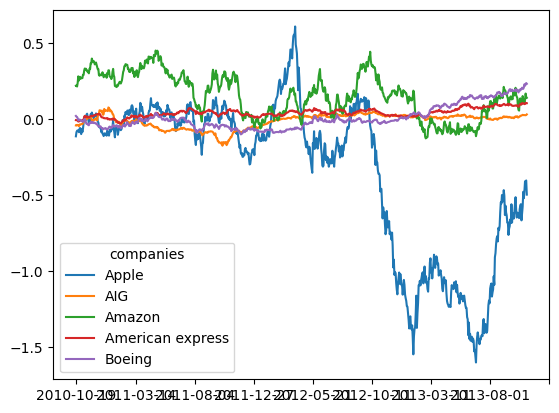

In [59]:
(
    movements
    # .query('labels == 1')
    .set_index('companies')
    .filter(regex = '\d-')
    .T
    .rolling(window = 200)
    .mean()
    .T
    .head(5)
    .T
    .plot()
    )

In [70]:
df = samples.filter(regex = '\d')
df

,0,1,2,3,4,5
0,242.0,23.2,25.4,30.0,38.4,13.4
1,290.0,24.0,26.3,31.2,40.0,13.8
2,340.0,23.9,26.5,31.1,39.8,15.1
3,363.0,26.3,29.0,33.5,38.0,13.3
4,430.0,26.5,29.0,34.0,36.6,15.1
...,...,...,...,...,...,...
80,950.0,48.3,51.7,55.1,16.2,11.2
81,1250.0,52.0,56.0,59.7,17.9,11.7
82,1600.0,56.0,60.0,64.0,15.0,9.6
83,1550.0,56.0,60.0,64.0,15.0,9.6


# 2: Visualizing hierarchies:
- "t-SNE": 2D map of dataset
- Hierarchical clustering

Hierarchical clustering: dendrogram
- read from bottom-up
- vertical lines: clusters
```python
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

mergins = linkage(samples, method = 'complete')

dendrogram(
    mergins,
    labels = country_names,
    leaf_rotation = 90,
    leaf_font_size = 6
)
plt.show()


Let's practice!

array([[33.        , 36.        ,  0.27162909,  2.        ],
       [21.        , 26.        ,  0.31365739,  2.        ],
       [18.        , 43.        ,  0.32846589,  3.        ],
       [38.        , 41.        ,  0.34657328,  2.        ],
       [19.        , 22.        ,  0.37233454,  2.        ]])

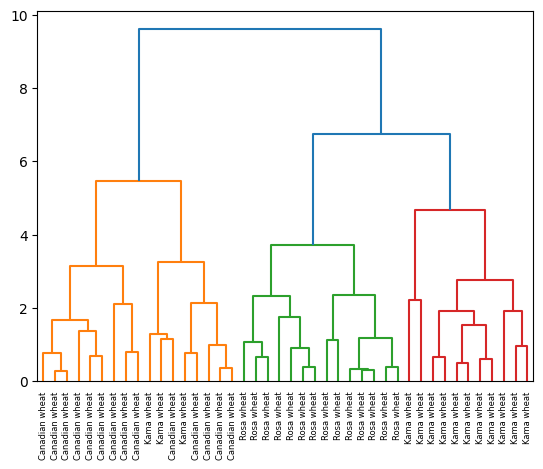

In [35]:
import pandas as pd 
from scipy.cluster.hierarchy import linkage, dendrogram 
import matplotlib.pyplot as plt 

samples_full = pd.read_csv('tables/grains.csv')
samples = samples.filter(regex = '\d')
# calculate the linkage
mergings = linkage(samples, method = 'complete')
display(mergings[:5,:])

# Plot the dendrogram
# dendrograThe code is plotting a dendrogram using the hierarchical clustering method.
varieties = samples_full['varieties'].values
dendrogram(
    mergings,
    labels = varieties, 
    leaf_rotation = 90, 
    leaf_font_size = 6
)
plt.show()

'mergings:'

array([[42.        , 49.        ,  0.58499795,  2.        ],
       [12.        , 57.        ,  0.67355098,  2.        ],
       [ 5.        , 26.        ,  0.69371159,  2.        ],
       [21.        , 48.        ,  0.75062554,  2.        ],
       [52.        , 60.        ,  0.78536856,  3.        ]])

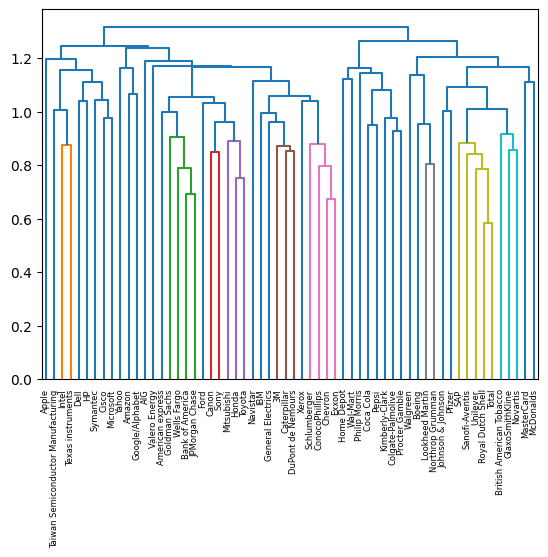

In [42]:
import pandas as pd 
from sklearn.preprocessing import normalize 
from scipy.cluster.hierarchy  import dendrogram, linkage

# import bank data
movement_full = pd.read_csv('tables/company-stock-movements-2010-2015-incl.csv')
movement_full = movement_full.rename(columns = {'Unnamed: 0': 'companies'})
movement = movement_full.filter(regex = '\d-')

# normalize the movements
normalized_movements = normalize(movement)

# calculate linkage
mergings = linkage(normalized_movements, method = 'complete')

display('mergings:', mergings[:5,:])

# plot
dendrogram(
    mergings, 
    labels = movement_full['companies'].values,
    leaf_rotation = 90,
    leaf_font_size= 6

)
plt.show()


Cluster labels in hierarchical clustering  

Linkage method:
- ex: complete: distance between clusters is max dist between samples
- ex: linkage(samples, method = 'complete')

```python
from scipy.cluster.hierarchy import linkage
mergings = likage(samples, method = 'complete')
from scipy.cluster.hierarchy import fcluster
labels = fcluster(mergings, 15, criterion = 'distance')
pairs = pd.DataFrame({'labels':labels, 'countries':country_names})
```


let's practice!

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero


,From country,To country,Jury A,Jury B,Jury C,Jury D,Jury E,Jury Rank,Televote Rank,Jury Points,Televote Points
0,Albania,Belgium,20,16,24,22,24,25,14,\n,\n
1,Albania,Czech Republic,21,15,25,23,16,22,22,\n,\n
2,Albania,The Netherlands,22,14,23,24,21,24,24,\n,\n
3,Albania,Azerbaijan,19,12,11,21,11,13,19,\n,\n
4,Albania,Hungary,8,13,9,14,9,10,10,1,1


,Jury A,Jury B,Jury C,Jury D,Jury E,Jury Rank,Televote Rank
To country,,,,,,,
Armenia,498,448,532,516,489,481,420
Australia,218,246,203,221,221,160,271
Austria,651,673,716,666,690,725,360
Azerbaijan,661,626,619,683,612,661,657
Belgium,506,455,418,442,441,441,559


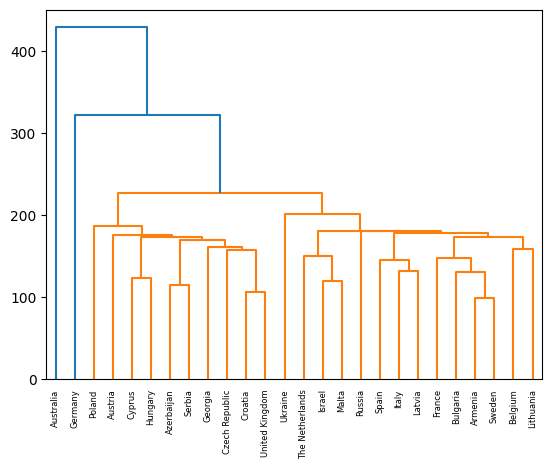

In [72]:
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram 

samples_full = pd.read_excel('tables/ESC-2016-grand_final-full_results.xls', header = 1)
samples = samples_full.set_index('To country').select_dtypes('number').groupby('To country').sum()
samples


display(samples_full.head(), samples.head())

#calculate the linkage: with single, it's bad
mergings = linkage(samples, method = 'single')

# plot dendrogram
dendrogram(
    mergings, 
    labels = samples.index.values,
    leaf_rotation=90,
    leaf_font_size=6
)
plt.show()